# ARGus v2: Random Forest con k = 6 y Random Undersampling (solo negativos)

Protocolo de la reunión del 18-oct:
1. Submuestrear **solo los negativos** (Random Undersampling) dentro del entrenamiento.
2. Tomar **todos los positivos** del entrenamiento.
3. Entrenar el Random Forest (k = 6).
4. Evaluar en un **test separado por gen** (distribución natural, sin balancear).
5. Guardar el modelo (joblib).
6. Evaluar el modelo guardado en los **1k + 1k genes** y comparar con ARGus v1, DeepARG y ARGNet.

**Importante (fuga de datos):** los 2000 genes del 1k+1k se **excluyen del entrenamiento y del test**.
Si no, el modelo ya los habría visto y la comparación saldría inflada.

El mismo cuaderno sirve para los sets de 90 % y 85 %: solo cambia `POSITIVOS_FILTRO` en la celda 1.

In [1]:
import pandas as pd
d = pd.read_csv("/mnt/c/Users/r4gbi/Desktop/Proyecto_Residencias/results/errores_id90/genes_1k1k_clasificados.csv")
print(d[(d.y==1) & (d.p_max>=0.5) & (d.p_max<0.6)].shape[0])
tp = d[(d.categoria=="TP") & (d.n_frag>1)]
print("TP con varios fragmentos:", len(tp),
      "| solo 1 fragmento sobre el umbral:", (tp.n_frag_sobre_umbral==1).sum())

293
TP con varios fragmentos: 741 | solo 1 fragmento sobre el umbral: 197


In [2]:
# ============ CELDA 1: configuración ============
import re, time, json, joblib
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (recall_score, precision_score, f1_score,
                             roc_auc_score, confusion_matrix)

# --- AJUSTA ESTA RUTA a tu carpeta data/interim ---
INTERIM = Path("/mnt/c/Users/r4gbi/Desktop/Proyecto_Residencias/data/interim")
assert INTERIM.exists(), "No encuentro la carpeta: revisa la ruta"

DATASET_FRAG = INTERIM / "dataset_fragmentado_500.tsv"       # id / lectura / etiqueta
DATASET_GENES = INTERIM / "dataset_etiquetado_completo.tsv"  # un gen por fila (1a col = id)
SET_1K1K      = INTERIM / "muestra_genes_labels.tsv"         # los 2000 genes de comparación
FASTA_1K1K    = INTERIM / "muestra_genes_completos.fasta"

# None = set de 95 % (el de siempre). Para 90 % / 85 %:
#   INTERIM / "positivo_id90_limpio.fasta"   o   INTERIM / "positivo_id85_limpio.fasta"
POSITIVOS_FILTRO = None
ETIQUETA_CORRIDA = "id95"          # solo para nombrar el modelo guardado

K = 6                              # indicación de la asesora
VENTANA = 500
SEED = 42
FRAC_TEST = 0.10                   # 1 de cada 10 grupos (StratifiedGroupKFold con 10 pliegues)
N_ARBOLES = 200
SALIDA = INTERIM.parent / "models"; SALIDA.mkdir(parents=True, exist_ok=True)
print("K =", K, "| columnas por fragmento:", 4**K)

K = 6 | columnas por fragmento: 4096


In [3]:
# ============ CELDA 2: cargar fragmentos, asignar gen y excluir los 2000 genes ============
frag = pd.read_csv(DATASET_FRAG, sep="\t")
print(frag.shape); print(frag.head(3))

# detectar columnas por contenido (no por nombre)
col_id  = frag.columns[0]
col_lab = next(c for c in frag.columns if c != col_id and set(frag[c].dropna().unique()) <= {0, 1})
cand    = [c for c in frag.columns if c not in (col_id, col_lab) and not pd.api.types.is_numeric_dtype(frag[c])]
col_seq = max(cand, key=lambda c: frag[c].astype(str).str.len().mean())
print("id:", col_id, "| secuencia:", col_seq, "| etiqueta:", col_lab)

genes_all = pd.read_csv(DATASET_GENES, sep="\t")
ids_gen = set(genes_all.iloc[:, 0].astype(str))

def gen_de(fid):
    # sube quitando sufijos (_frag3, |3, _3 ...) hasta encontrar un id que exista en la tabla de genes
    s = str(fid)
    while s not in ids_gen:
        m = re.search(r"[_|:\-.][^_|:\-.]*$", s)
        if not m: return str(fid)
        s = s[:m.start()]
    return s
# el gen es el id sin el sufijo "__fragN"
frag["gen"] = frag[col_id].str.replace(r"__frag\d+$", "", regex=True)
print("genes distintos:", frag["gen"].nunique(), "| fragmentos:", len(frag))

# --- excluir los 2000 genes del 1k+1k ---
lab1k = pd.read_csv(SET_1K1K, sep="\t")
ids_1k = set(lab1k.iloc[:, 0].astype(str))
genes_frag = set(frag["gen"])
excluir = ids_1k & genes_frag
faltan = ids_1k - excluir
if faltan:  # respaldo: probar sin el prefijo del genoma (GCF_...|)
    variantes = {}
    for g in genes_frag:
        variantes.setdefault(g.split("|", 1)[-1], g)
    for f in list(faltan):
        if f in variantes: excluir.add(variantes[f]); faltan.discard(f)
print("genes del 1k+1k encontrados en el dataset:", len(excluir), "de", len(ids_1k))
if faltan: print("NO encontrados (ejemplos):", list(faltan)[:5], "| ejemplos de gen:", list(genes_frag)[:3])

mask_1k = frag["gen"].isin(excluir)
print("fragmentos excluidos:", mask_1k.sum())
print(frag[mask_1k].drop_duplicates("gen")["etiqueta"].value_counts())   # esperado: ~1000 y ~1000
pool = frag[~mask_1k].reset_index(drop=True)

(72874, 3)
                                                  id  \
0  CARD|gb|AF028812.1|+|392-887|ARO:3002867|dfrF_...   
1  CARD|gb|AY234334.1|+|0-846|ARO:3000600|Erm(34)...   
2  CARD|gb|AY234334.1|+|0-846|ARO:3000600|Erm(34)...   

                                             lectura  etiqueta  
0  ATGATAGGTTTGATTGTTGCGAGGTCAAAGAATAATGTTATAGGCA...         1  
1  ATGACGAAAAAAATGAACAAGTATAATGGGAAAAAACTTAGCCGTG...         1  
2  TGACATCCACTATGAAAGGGGAATTTCCAGAAGTTCATTTTCGCCG...         1  
id: id | secuencia: lectura | etiqueta: etiqueta
genes distintos: 30741 | fragmentos: 72874
genes del 1k+1k encontrados en el dataset: 2000 de 2000
fragmentos excluidos: 4667
etiqueta
1    1000
0    1000
Name: count, dtype: int64


In [4]:
# ============ CELDA 3: k-mers rápidos (vectorizado) ============
LUT = np.full(256, 4, dtype=np.int8)
for i, b in enumerate(b"ACGT"): LUT[b] = i
POT = (4 ** np.arange(K - 1, -1, -1)).astype(np.int64)

def vector_kmer(seq):
    # frecuencia relativa de los 4^K k-mers; ventanas con '0' (relleno) u otra base se ignoran
    a = LUT[np.frombuffer(seq.upper().encode(), dtype=np.uint8)]
    n = len(a) - K + 1
    out = np.zeros(4 ** K, dtype=np.float32)
    if n <= 0: return out
    win = np.lib.stride_tricks.sliding_window_view(a, K)
    ok = (win < 4).all(axis=1)
    if not ok.any(): return out
    idx = (win[ok].astype(np.int64) * POT).sum(axis=1)
    out += np.bincount(idx, minlength=4 ** K).astype(np.float32)
    return out / out.sum()

def matriz(seqs):
    X = np.empty((len(seqs), 4 ** K), dtype=np.float32)
    for i, s in enumerate(seqs): X[i] = vector_kmer(s)
    return X

# prueba rápida: un fragmento con relleno
print(vector_kmer("ACGT" * 10 + "0" * 20).sum())   # debe ser 1.0

1.0


In [5]:
# ============ CELDA 4: partición por gen (train / test) y Random Undersampling SOLO en train ============
y_all = pool[col_lab].values
g_all = pool["gen"].values

# Un pliegue de StratifiedGroupKFold(10) = 10 % de los genes para test, sin que un gen quede en ambos lados
sgkf = StratifiedGroupKFold(n_splits=int(round(1 / FRAC_TEST)), shuffle=True, random_state=SEED)
tr, te = next(sgkf.split(np.zeros(len(y_all)), y_all, g_all))
assert not set(g_all[tr]) & set(g_all[te]), "FUGA: un gen aparece en train y test"

rng = np.random.default_rng(SEED)
pos = tr[y_all[tr] == 1]                                   # TODOS los positivos del train
neg = tr[y_all[tr] == 0]
neg_ds = rng.choice(neg, size=len(pos), replace=False)     # Random Undersampling (solo negativos)
tr_bal = np.concatenate([pos, neg_ds]); rng.shuffle(tr_bal)

print(f"train original : pos={len(pos):,}  neg={len(neg):,}  (razón {len(neg)/len(pos):.1f}:1)")
print(f"train balanceado: pos={len(pos):,}  neg={len(neg_ds):,}")
print(f"test (natural) : pos={(y_all[te]==1).sum():,}  neg={(y_all[te]==0).sum():,}")

train original : pos=6,506  neg=54,880  (razón 8.4:1)
train balanceado: pos=6,506  neg=6,506
test (natural) : pos=723  neg=6,098


In [6]:
# ============ CELDA 5: features (solo de lo necesario -> ahorra RAM) y entrenamiento ============
t0 = time.time()
seqs = pool[col_seq].astype(str).values
X_tr = matriz(seqs[tr_bal]); y_tr = y_all[tr_bal]
print("X_train:", X_tr.shape, f"{X_tr.nbytes/1e9:.2f} GB", f"({time.time()-t0:.0f}s)")

rf = RandomForestClassifier(n_estimators=N_ARBOLES, n_jobs=-1, random_state=SEED)
rf.fit(X_tr, y_tr)
print(f"RF entrenado en {time.time()-t0:.0f}s")

X_train: (13012, 4096) 0.21 GB (1s)
RF entrenado en 12s


In [7]:
# ============ CELDA 6: evaluación en el TEST (distribución natural) ============
X_te = matriz(seqs[te]); y_te = y_all[te]
p_te = rf.predict_proba(X_te)[:, 1]; pred_te = (p_te >= 0.5).astype(int)

def metricas(y, pred, p=None):
    d = dict(recall=recall_score(y, pred), precision=precision_score(y, pred, zero_division=0),
             f1=f1_score(y, pred))
    if p is not None: d["auc"] = roc_auc_score(y, p)
    return d

m_frag = metricas(y_te, pred_te, p_te)
print("== FRAGMENTO ==", {k: round(v, 3) for k, v in m_frag.items()})
print(confusion_matrix(y_te, pred_te))

# nivel gen: un gen es ARG si ALGÚN fragmento lo es (misma regla que en la comparación)
df_te = pd.DataFrame({"gen": g_all[te], "y": y_te, "pred": pred_te, "p": p_te})
gg = df_te.groupby("gen").agg(y=("y", "max"), pred=("pred", "max"), p=("p", "max"))
m_gen = metricas(gg.y, gg.pred, gg.p)
print("== GEN (any) ==", {k: round(v, 3) for k, v in m_gen.items()}, "| genes test:", len(gg))

== FRAGMENTO == {'recall': 0.748, 'precision': 0.369, 'f1': 0.495, 'auc': 0.873}
[[5174  924]
 [ 182  541]]
== GEN (any) == {'recall': 0.867, 'precision': 0.284, 'f1': 0.428, 'auc': 0.878} | genes test: 2874


In [8]:
# ============ CELDA 7: guardar el modelo ============
ruta_modelo = SALIDA / f"argus_rf_k{K}_{ETIQUETA_CORRIDA}.joblib"
joblib.dump({"modelo": rf, "K": K, "ventana": VENTANA, "relleno": "0",
             "regla_gen": "any", "umbral": 0.5, "semilla": SEED,
             "metricas_test_fragmento": m_frag, "metricas_test_gen": m_gen}, ruta_modelo, compress=3)
print("guardado:", ruta_modelo, f"{ruta_modelo.stat().st_size/1e6:.0f} MB")

guardado: /mnt/c/Users/r4gbi/Desktop/Proyecto_Residencias/data/models/argus_rf_k6_id95.joblib 13 MB


## Comparación en los 1k + 1k
Se carga el modelo **guardado** (como lo hará la GUI) y se evalúa sobre los 2000 genes completos, que el modelo nunca vio.

In [9]:
# ============ CELDA 8: ARGus v2 sobre los 2000 genes (modelo cargado desde disco) ============
pk = joblib.load(ruta_modelo); rf2 = pk["modelo"]

def leer_fasta(path):
    d, cur = {}, None
    for l in open(path):
        l = l.strip()
        if l.startswith(">"): cur = l[1:].split()[0]; d[cur] = []
        elif cur: d[cur].append(l)
    return {k: "".join(v) for k, v in d.items()}

def fragmentar(seq, ventana=500):
    seq = seq.upper(); L = len(seq)
    if L < ventana: return [seq + "0" * (ventana - L)]
    n = L // ventana; fr = [seq[i*ventana:(i+1)*ventana] for i in range(n)]
    if L % ventana: fr.append(seq[-ventana:])
    return fr

fa = leer_fasta(FASTA_1K1K)
y_1k = dict(zip(lab1k.iloc[:, 0].astype(str), lab1k.iloc[:, 1].astype(int)))
ids = [i for i in fa if i in y_1k]
print("genes con secuencia y etiqueta:", len(ids), "de", len(y_1k))

filas = []
for gid in ids:
    fr = fragmentar(fa[gid], pk["ventana"])
    p = rf2.predict_proba(matriz(fr))[:, 1]
    filas.append((gid, y_1k[gid], int((p >= pk["umbral"]).any()), p.max()))
r1k = pd.DataFrame(filas, columns=["gen", "y", "pred", "p"])
m_v2 = metricas(r1k.y, r1k.pred, r1k.p)
print("ARGus v2 (1k+1k):", {k: round(v, 3) for k, v in m_v2.items()})
print(confusion_matrix(r1k.y, r1k.pred))

genes con secuencia y etiqueta: 2000 de 2000
ARGus v2 (1k+1k): {'recall': 0.861, 'precision': 0.784, 'f1': 0.821, 'auc': 0.902}
[[763 237]
 [139 861]]


In [10]:
# ============ CELDA 9: tabla comparativa (ARGus v1, v2, ARGNet-s, DeepARG) ============
ARGUS_V1 = dict(recall=0.893, precision=0.745, f1=0.813)
ARGNET_F = Path.home() / "ARGNet/results/argnet_reads150.txt"      # argnet-s, lecturas de 150 nt
DEEP_F   = INTERIM.parent.parent / "results" / "deeparg_genes_id30.mapping.ARG"

def leer_argnet(path):
    t = pd.read_csv(path, sep="\t")
    col = next(c for c in t.columns if "prediction" in c.lower())
    t["arg"] = t[col].astype(str).str.strip().str.upper().eq("ARG")
    return t

def pred_argnet_reads(path, ids):
    t = leer_argnet(path)
    genes = set(ids)
    def gen_de(rid):                       # quita sufijos (__r0, etc.) hasta dar con un gen de la muestra
        s = str(rid).strip()
        while s not in genes:
            m = re.search(r"[_|:\-.][^_|:\-.]*$", s)
            if not m: return None
            s = s[:m.start()]
        return s
    t["gen"] = t.iloc[:, 0].map(gen_de)
    por_gen = t.dropna(subset=["gen"]).groupby("gen")["arg"].max()     # regla OR
    print(f"ARGNet-s: {len(t)} lecturas | asignadas: {t.gen.notna().sum()} | genes con lectura: {len(por_gen)} de {len(genes)}")
    return ids.map(lambda g: int(por_gen.get(g, False)))

def pred_deeparg(path, ids):
    t = pd.read_csv(path, sep="\t", comment="#", header=None)          # read_id = columna 3
    vistos = set(t.iloc[:, 3].astype(str))
    vistos |= {v.rsplit("_", 1)[0] for v in vistos}
    print(f"DeepARG: genes de la muestra con hit: {ids.isin(vistos).sum()}")
    return ids.map(lambda g: int(g in vistos))

tabla = {"ARGus v1 (k=4)": ARGUS_V1, "ARGus v2 (k=6, undersampling)": m_v2}
for nombre, f, ruta in [("ARGNet (argnet-s, OR)", pred_argnet_reads, ARGNET_F),
                        ("DeepARG (id30)", pred_deeparg, DEEP_F)]:
    try:
        p = f(ruta, r1k.gen)
        tabla[nombre] = metricas(r1k.y, p)
        print(nombre); print(confusion_matrix(r1k.y, p))
    except Exception as e:
        print(f"{nombre}: ERROR ->", repr(e))

res = pd.DataFrame(tabla).T[["recall", "precision", "f1"]].round(3)
print(res)
res.to_csv(SALIDA / f"comparacion_{ETIQUETA_CORRIDA}.csv")

ARGNet-s: 11392 lecturas | asignadas: 11392 | genes con lectura: 1977 de 2000
ARGNet (argnet-s, OR)
[[921  79]
 [411 589]]
DeepARG: genes de la muestra con hit: 736
DeepARG (id30)
[[984  16]
 [280 720]]
                               recall  precision     f1
ARGus v1 (k=4)                  0.893      0.745  0.813
ARGus v2 (k=6, undersampling)   0.861      0.784  0.821
ARGNet (argnet-s, OR)           0.589      0.882  0.706
DeepARG (id30)                  0.720      0.978  0.829


In [11]:
# ============ CELDA A: reporte con el formato del primer modelo ============
from sklearn.metrics import classification_report

def reporte(y, pred, p=None, titulo=""):
    print(f"=== {titulo} ===")
    cm = confusion_matrix(y, pred)
    print("Matriz de confusión:")
    print("                Predijo NEG  Predijo POS")
    print(f"  Real NEG (0)  {cm[0,0]:>11,}  {cm[0,1]:>11,}")
    print(f"  Real POS (1)  {cm[1,0]:>11,}  {cm[1,1]:>11,}\n")
    print(classification_report(y, pred, target_names=["no_resist (0)", "resist (1)"], digits=3))
    if p is not None: print(f"AUC-ROC: {roc_auc_score(y, p):.3f}")
    print()

reporte(y_te, pred_te, p_te, "TEST holdout (por fragmento)")
reporte(gg.y, gg.pred, gg.p, "TEST holdout (por gen, regla any)")
reporte(r1k.y, r1k.pred, r1k.p, "1k + 1k genes (ARGus v2, por gen)")

=== TEST holdout (por fragmento) ===
Matriz de confusión:
                Predijo NEG  Predijo POS
  Real NEG (0)        5,174          924
  Real POS (1)          182          541

               precision    recall  f1-score   support

no_resist (0)      0.966     0.848     0.903      6098
   resist (1)      0.369     0.748     0.495       723

     accuracy                          0.838      6821
    macro avg      0.668     0.798     0.699      6821
 weighted avg      0.903     0.838     0.860      6821

AUC-ROC: 0.873

=== TEST holdout (por gen, regla any) ===
Matriz de confusión:
                Predijo NEG  Predijo POS
  Real NEG (0)        1,846          705
  Real POS (1)           43          280

               precision    recall  f1-score   support

no_resist (0)      0.977     0.724     0.832      2551
   resist (1)      0.284     0.867     0.428       323

     accuracy                          0.740      2874
    macro avg      0.631     0.795     0.630      2874
 weig

In [12]:
# ============ CELDA B: validación cruzada 10-fold (k=6, undersampling solo en train) ============
import warnings; warnings.filterwarnings("ignore")

X_pool = matriz(seqs)                       # todos los fragmentos del pool (sin los 2000 genes)
print("X_pool:", X_pool.shape, f"{X_pool.nbytes/1e9:.2f} GB")

skf = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEED)
rng = np.random.default_rng(SEED)
oof_pred = np.zeros(len(y_all), dtype=int); oof_p = np.zeros(len(y_all)); met = []

for i, (tr_i, va_i) in enumerate(skf.split(X_pool, y_all, g_all), 1):
    pos = tr_i[y_all[tr_i] == 1]; neg = tr_i[y_all[tr_i] == 0]
    bal = np.concatenate([pos, rng.choice(neg, size=len(pos), replace=False)])   # solo negativos
    rf_i = RandomForestClassifier(n_estimators=N_ARBOLES, n_jobs=-1, random_state=SEED)
    rf_i.fit(X_pool[bal], y_all[bal])
    p_i = rf_i.predict_proba(X_pool[va_i])[:, 1]; pr_i = (p_i >= 0.5).astype(int)
    oof_p[va_i] = p_i; oof_pred[va_i] = pr_i
    met.append(metricas(y_all[va_i], pr_i, p_i))
    print(f"pliegue {i}/10  recall={met[-1]['recall']:.3f}  auc={met[-1]['auc']:.3f}")

M = pd.DataFrame(met)
print("\n=== PROMEDIOS (10-fold) ===")
for nombre, c in [("Recall", "recall"), ("Precision", "precision"), ("F1", "f1"), ("AUC-ROC", "auc")]:
    print(f"{nombre + ':':<11}{M[c].mean():.3f} +/- {M[c].std():.3f}")
print()
reporte(y_all, oof_pred, oof_p, "ACUMULADO de los 10 pliegues (por fragmento)")

# mismo reporte a nivel gen (regla any), con las predicciones fuera de pliegue
gdf = pd.DataFrame({"gen": g_all, "y": y_all, "pred": oof_pred, "p": oof_p}) \
        .groupby("gen").agg(y=("y", "max"), pred=("pred", "max"), p=("p", "max"))
reporte(gdf.y, gdf.pred, gdf.p, "ACUMULADO de los 10 pliegues (por gen, any)")
del X_pool

X_pool: (68207, 4096) 1.12 GB
pliegue 1/10  recall=0.766  auc=0.876
pliegue 2/10  recall=0.752  auc=0.882
pliegue 3/10  recall=0.798  auc=0.889
pliegue 4/10  recall=0.761  auc=0.884
pliegue 5/10  recall=0.748  auc=0.865
pliegue 6/10  recall=0.726  auc=0.865
pliegue 7/10  recall=0.757  auc=0.879
pliegue 8/10  recall=0.725  auc=0.862
pliegue 9/10  recall=0.730  auc=0.869
pliegue 10/10  recall=0.712  auc=0.856

=== PROMEDIOS (10-fold) ===
Recall:    0.748 +/- 0.025
Precision: 0.368 +/- 0.011
F1:        0.494 +/- 0.014
AUC-ROC:   0.873 +/- 0.011

=== ACUMULADO de los 10 pliegues (por fragmento) ===
Matriz de confusión:
                Predijo NEG  Predijo POS
  Real NEG (0)       51,713        9,265
  Real POS (1)        1,825        5,404

               precision    recall  f1-score   support

no_resist (0)      0.966     0.848     0.903     60978
   resist (1)      0.368     0.748     0.494      7229

     accuracy                          0.837     68207
    macro avg      0.667     0.

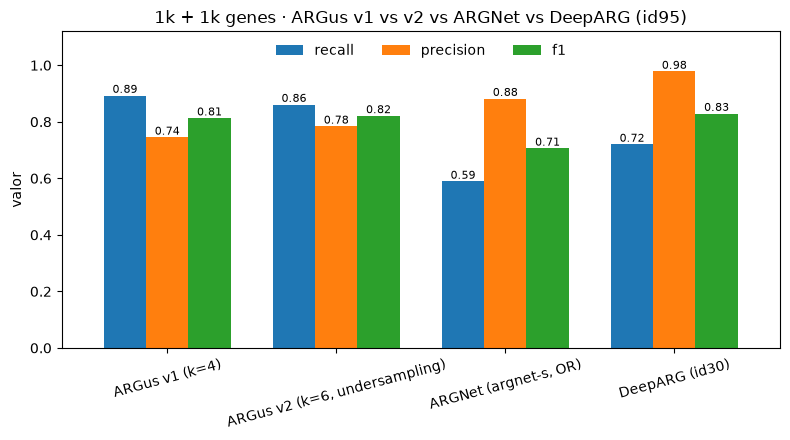

In [13]:
# ============ CELDA 10: gráfica (solo los 3 modelos + v1) ============
import matplotlib.pyplot as plt
ax = res.plot.bar(figsize=(8, 4.5), rot=15, width=0.75)
ax.set_ylim(0, 1); ax.set_ylabel("valor"); ax.set_title(f"1k + 1k genes · ARGus v1 vs v2 vs ARGNet vs DeepARG ({ETIQUETA_CORRIDA})")
for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=8)
ax.set_ylim(0, 1.12); ax.legend(loc="upper center", ncol=3, frameon=False)
plt.tight_layout(); plt.savefig(SALIDA / f"comparacion_{ETIQUETA_CORRIDA}.png", dpi=200); plt.show()